In [46]:
import numpy as np
import torch
import os
import glob


In [216]:
script_file_path = 'bash_scripts/test.sh'
watch_list = []
with open(script_file_path, 'r', encoding='utf-8') as f:
    for line in f:
        if not line.startswith('for'):
            continue
        watch = line.split('in')[-1].split()
        watch_list.extend(watch)
print(watch_list)

config_file_path = 'bash_scripts/config/test.tsv'
new_f = []
with open(config_file_path, 'r', encoding='utf-8') as f:
    for i, line in enumerate(f):
        line = line.strip()  # 줄 끝의 개행 문자 제거
        if not line or line.startswith('#'):
            new_f.append(line)
            continue  # 빈 줄은 건너뛰기

        line = line.replace('\t\t','\t')
        cols = line.split('\t')  # 탭으로 분리
        ckpt_path = f'ckpt/{cols[3]}/usage{cols[4]}/{cols[0]}_{cols[2]}_{cols[1]}/{cols[12]}_init{cols[8]}_{cols[6]}/snr_sg{cols[10]}_snvr_svg{cols[11]}'
        seeds = cols[7].split(',')

        if len(cols) >= 14:
            new_f.append(line)
            if str(i+1) in watch_list: 
                print(f'line {i+1}: {line}')
            continue

        best_accs = []
        for root, dirs, files in os.walk(ckpt_path):
            if 'training_stats.npy' not in files:
                continue
            ckpt = torch.load(os.path.join(root, 'epoch_best.ckpt'))
            best_accs.append(ckpt['test_acc'])
        
        cols = cols[:13]
        if best_accs:
            cols.append('%.2f ± %.2f' % (np.mean(best_accs), np.std(best_accs))) 
        new_line = '\t'.join(cols)
        if str(i+1) in watch_list:
            print(f'line {i+1}: {new_line} ({len(best_accs)})')

        new_f.append(new_line if len(best_accs) == len(seeds) else line)
                    
with open(config_file_path, 'w', encoding='utf-8') as f:
    for line in new_f:
        f.write(line + '\n')

['58', '59', '61']
line 58: vgg_cifar	1	16	cifar100	0.2	200	cosine	43,37,13,51,71,24,68,16,77,98	0.05	0.0005	0	0	SGDSNR	45.37 ± 0.66
line 59: vgg_cifar	1	16	cifar100	0.2	200	cosine	43,37,13,51,71,24,68,16,77,98	0.05	0.0005	0.005	0	SGDSNR	49.05 ± 0.94
line 61: vgg_cifar	1	16	cifar100	0.2	200	cosine	43,37,13,51,71,24,68,16,77,98	0.05	0.0005	0.005	0.01	SGDSNR	48.87 ± 0.49 (5)


In [204]:
ckpt = np.load('ckpt/cifar100/usage0.2/vgg_cifar_16_1/SGDSNR_init0.05_cosine/snr_sg0.005_snvr_svg0/epochs200_wd0.0005_seed43/training_stats.npy', allow_pickle=True).item()
ckpt['elapsed_time'][-1]/60


16.59701553185781

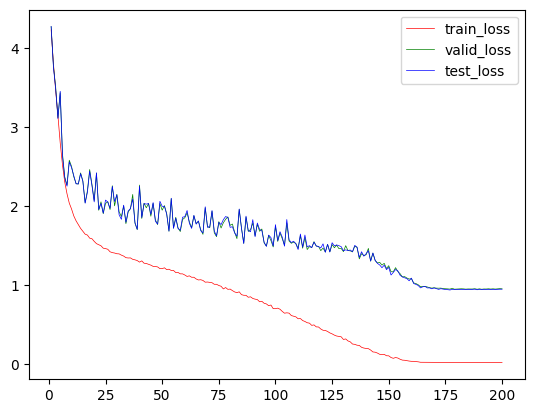

dict_keys(['train_loss', 'train_acc', 'valid_loss', 'valid_acc', 'test_loss', 'test_acc', 'current_lr', 'schedule_next_lr', 'epoch_time', 'elapsed_time', 'train_idx', 'valid_idx'])


In [ ]:

import matplotlib.pyplot as plt

ckpt = np.load('ckpt/cifar100/resnet_34_1/SGDSNR_init0.1_cosine/snr_sg0.015_snvr_svg1.0/epochs200_wd0.0005_seed43/training_stats.npy', allow_pickle=True).item()

loss_names = ['train_loss', 'valid_loss', 'test_loss']
colors = 'rgb'

for idx, loss_name in enumerate(loss_names):
    y = ckpt[loss_name]
    x = np.arange(1, len(y)+1)
    plt.plot(x, y, c=colors[idx], label=loss_name, alpha=1, linewidth=0.5)
plt.legend()
plt.show()

print(ckpt.keys())

Initialize the VGG by default width factor 1
0.7030010759557024
Initialize the VGG by default width factor 1
0.3158487204766713
Initialize the VGG by default width factor 1
0.25574025996846783


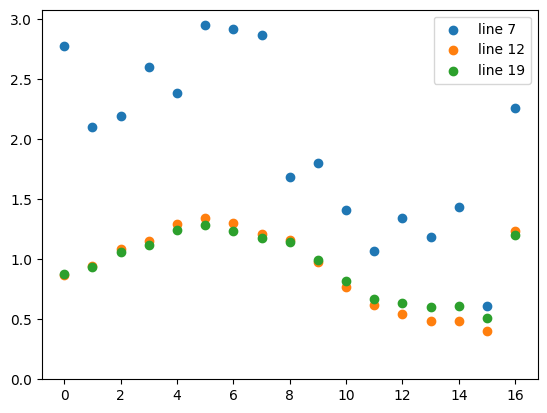

In [145]:
from networks import *
from sgdsnr import compute_weight
import matplotlib.pyplot as plt

watch_list = [7,12,19]

config_file_path = 'bash_scripts/config/test.tsv'
new_f = []
with open(config_file_path, 'r', encoding='utf-8') as f:
    for idx, line in enumerate(f):
        if idx+1 not in watch_list:
            continue

        line = line.replace('\t\t','\t')
        cols = line.split('\t')  # 탭으로 분리
        ckpt_path = f'ckpt/{cols[3]}/usage{cols[4]}/{cols[0]}_{cols[2]}_{cols[1]}/{cols[12]}_init{cols[8]}_{cols[6]}/snr_sg{cols[10]}_snvr_svg{cols[11]}'
        seeds = cols[7].split(',')

        best_accs = []
        for root, dirs, files in os.walk(ckpt_path):
            if 'training_stats.npy' not in files:
                continue
            ckpt = torch.load(os.path.join(root, 'epoch_best.ckpt'))
            break

        model = VGG_cifar(19, 100, 1)
        model.load_state_dict(ckpt['net'])
        model.cuda()

        sn_list = []
        for i, p in enumerate(model.parameters()):
            if p.dim() > 1:
                sn, uv = compute_weight(p, n_power_iterations=10)
                sn_list.append(sn.flatten()[0].item())
            else:
                pass
        print(np.std(sn_list))
        plt.scatter(range(len(sn_list)), sn_list, label=f'line {idx+1}')
plt.ylim(0.0)
plt.legend()
plt.show()